<a href="https://colab.research.google.com/github/brenoprato/calculo-numerico/blob/main/atividade_gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:64: SyntaxWarning: invalid escape sequence '\|'
<>:64: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_8913/3547840304.py:64: SyntaxWarning: invalid escape sequence '\|'
  plt.title('b) Erro $\||x^{(k)} - x^{(k-1)}\||_{\infty}$ em escala logarítmica')


=== QUESTÃO 5 ===
Número de iterações realizadas: 6
Solução aproximada obtida: x = 1.00000003, y = 1.99999998, z = -1.00000001

=== QUESTÃO 6: TABELA DE ITERAÇÕES ===
 k      x^(k)      y^(k)       z^(k)  ||x^(k) - x^(k-1)||_inf
 0 0.00000000 0.00000000  0.00000000                      NaN
 1 0.60000000 2.05454545 -0.91454545               2.05454545
 2 0.98836364 2.00671074 -0.99700165               0.38836364
 3 1.00007140 2.00027907 -0.99998637               0.01170777
 4 1.00002518 2.00000353 -1.00000468               0.00027554
 5 1.00000129 1.99999969 -1.00000029               0.00002389
 6 1.00000003 1.99999998 -1.00000001               0.00000126


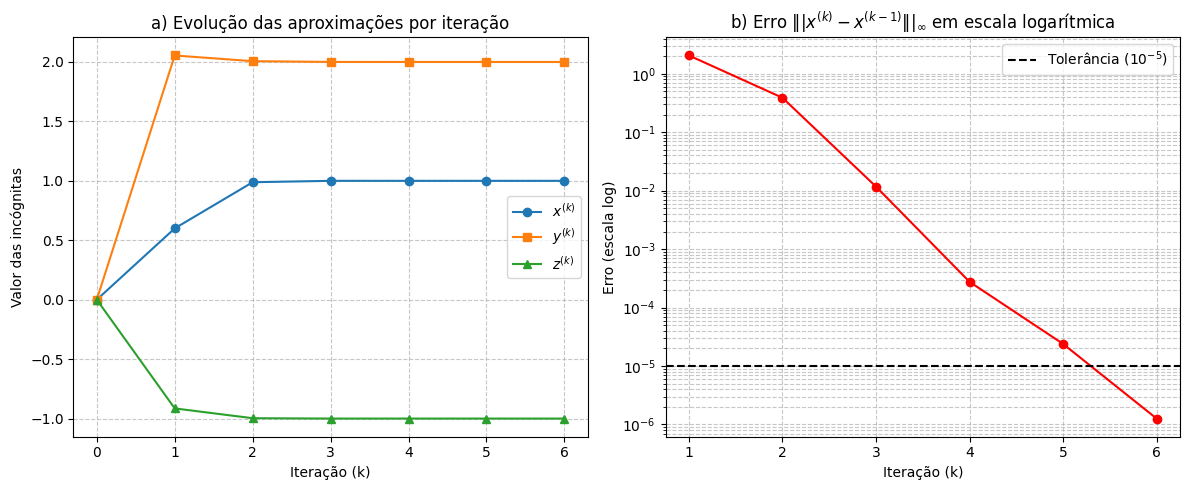

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 5. Implementação do Método de Gauss-Seidel
tol = 1e-5
max_iter = 100

# Aproximação inicial x^(0) = (0, 0, 0)
x_atual = np.array([0.0, 0.0, 0.0])

# Listas para armazenar o histórico
historico = [[0, x_atual[0], x_atual[1], x_atual[2], np.nan]]

for k in range(1, max_iter + 1):
    x_ant = x_atual.copy()

    # Fórmulas iterativas de Gauss-Seidel
    x_novo = (6 + x_ant[1] - 2 * x_ant[2]) / 10
    y_novo = (22 + x_novo + x_ant[2]) / 11
    z_novo = (-10 - 2 * x_novo + y_novo) / 10

    x_atual = np.array([x_novo, y_novo, z_novo])

    # Cálculo do erro na norma infinito
    erro = np.max(np.abs(x_atual - x_ant))
    historico.append([k, x_novo, y_novo, z_novo, erro])

    if erro < tol:
        break

print("=== QUESTÃO 5 ===")
print(f"Número de iterações realizadas: {k}")
print(f"Solução aproximada obtida: x = {x_atual[0]:.8f}, y = {x_atual[1]:.8f}, z = {x_atual[2]:.8f}\n")

# 6. Organização dos resultados em Tabela
print("=== QUESTÃO 6: TABELA DE ITERAÇÕES ===")
df = pd.DataFrame(historico, columns=['k', 'x^(k)', 'y^(k)', 'z^(k)', '||x^(k) - x^(k-1)||_inf'])
print(df.to_string(index=False, float_format=lambda x: f"{x:.8f}"))

# 7. Gráficos
k_vals = df['k']
k_erro = df['k'][1:]
erros = df['||x^(k) - x^(k-1)||_inf'][1:]

plt.figure(figsize=(12, 5))

# Gráfico 7a) Evolução das aproximações
plt.subplot(1, 2, 1)
plt.plot(k_vals, df['x^(k)'], marker='o', label='$x^{(k)}$')
plt.plot(k_vals, df['y^(k)'], marker='s', label='$y^{(k)}$')
plt.plot(k_vals, df['z^(k)'], marker='^', label='$z^{(k)}$')
plt.title('a) Evolução das aproximações por iteração')
plt.xlabel('Iteração (k)')
plt.ylabel('Valor das incógnitas')
plt.xticks(k_vals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Gráfico 7b) Erro em escala logarítmica
plt.subplot(1, 2, 2)
plt.semilogy(k_erro, erros, marker='o', color='red', linestyle='-')
plt.axhline(tol, color='black', linestyle='--', label='Tolerância ($10^{-5}$)')
plt.title('b) Erro $\||x^{(k)} - x^{(k-1)}\||_{\infty}$ em escala logarítmica')
plt.xlabel('Iteração (k)')
plt.ylabel('Erro (escala log)')
plt.xticks(k_erro)
plt.grid(True, which="both", linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()